# Descomposición de las series de la cartera (issue #20)

Separa la evolución de cada activo en **tendencia**, **estacionalidad** y **residuo**.

**Dataset de entrada:** precios diarios de JPM, MSFT y WMT descargados de **Yahoo Finance** con `yfinance` (desde 2016-01-01 hasta hoy). No se lee ningún fichero local.

**Decisiones (procesamiento justificado)**
- **Frecuencia mensual** (último cierre del mes): la estacionalidad que interesa es anual y en datos diarios el ruido la tapa. Hay ~10 años, es decir, ~10 ciclos completos.
- **Periodo 12**: un ciclo estacional = un año de datos mensuales.
- **Log(precio) + modelo aditivo**: los precios crecen de forma exponencial y las oscilaciones son proporcionales al nivel; el log lo estabiliza (equivale a un modelo multiplicativo sobre el precio). Se comprueba con datos en la celda 3.
- **Cierre ajustado** (dividendos y splits), para que no haya saltos artificiales.

In [1]:
# ---- Imports y configuración ------------------------------------------------
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import Markdown, display
from statsmodels.tsa.seasonal import seasonal_decompose

# Cartera y color FIJO por activo (el mismo en todos los gráficos)
ACTIVOS = {
    "JPM":  {"nombre": "JPMorgan",  "color": "#1f77b4"},
    "MSFT": {"nombre": "Microsoft", "color": "#2ca02c"},
    "WMT":  {"nombre": "Walmart",   "color": "#ff7f0e"},
}
PERIODO = 12                       # 12 meses = 1 año
DIR_OUT = Path("outputs/series_temporales")   # carpeta ignorada por git
DIR_OUT.mkdir(parents=True, exist_ok=True)

In [2]:
# ---- Descarga y paso a mensual ----------------------------------------------
# Cierre ajustado diario -> último cierre de cada mes
diario = yf.download(list(ACTIVOS), start="2016-01-01", auto_adjust=True, progress=False)["Close"]
mensual = diario[list(ACTIVOS)].resample("ME").last()
if not diario.index.max().is_month_end:   # el mes en curso está incompleto: se descarta
    mensual = mensual.iloc[:-1]

log_mensual = np.log(mensual)             # log para estabilizar la varianza
print(f"Descarga: {pd.Timestamp.today():%Y-%m-%d} | "
      f"{mensual.index[0]:%m/%Y} → {mensual.index[-1]:%m/%Y} | {len(mensual)} meses | "
      f"nulos: {int(mensual.isna().sum().sum())}")

Descarga: 2026-09-30 | 01/2016 → 09/2026 | 129 meses | nulos: 0


In [3]:
# ---- Contraste aditivo vs multiplicativo (sobre el precio sin log) ----------
# Un modelo es adecuado si el tamaño del residuo NO crece con el nivel de la serie.
# Se mide con la correlación entre tendencia y |residuo|: cerca de 0 = residuo estable.
filas = []
for s in ACTIVOS:
    fila = {"activo": s}
    for modelo in ("additive", "multiplicative"):
        d = seasonal_decompose(mensual[s], model=modelo, period=PERIODO)
        resid = (d.resid - (1 if modelo == "multiplicative" else 0)).abs()   # multiplicativo: ratio alrededor de 1
        fila[modelo] = round(d.trend.corr(resid), 2)
    filas.append(fila)
pd.DataFrame(filas).set_index("activo")

,additive,multiplicative
activo,,
JPM,0.49,-0.06
MSFT,0.57,0.34
WMT,0.53,0.07


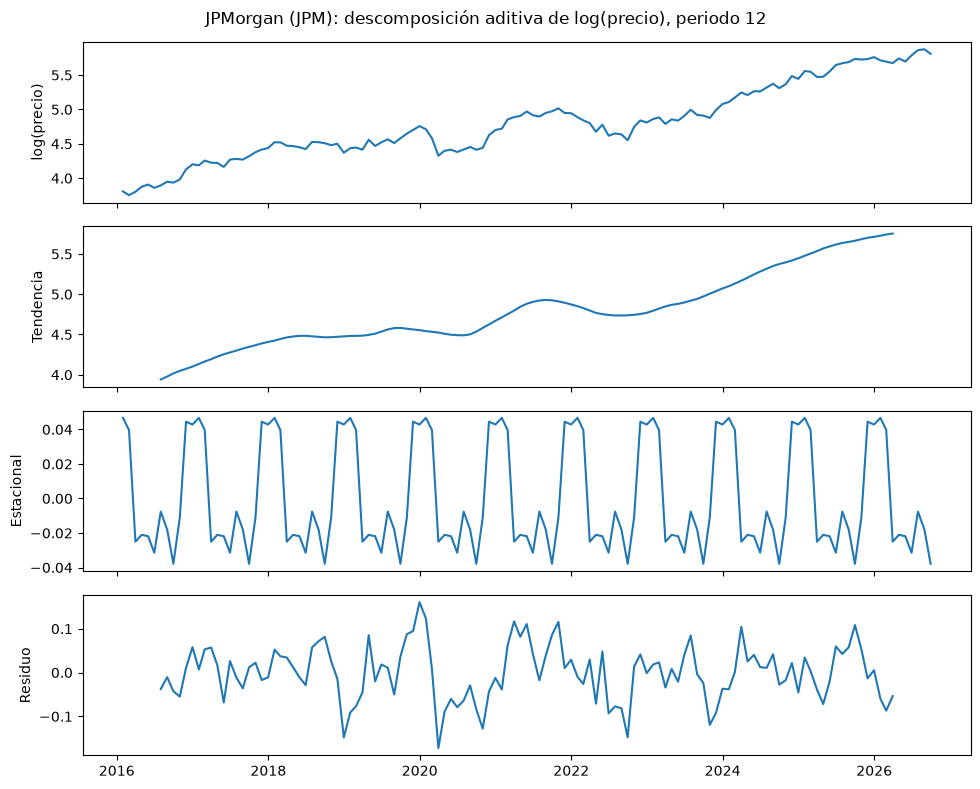

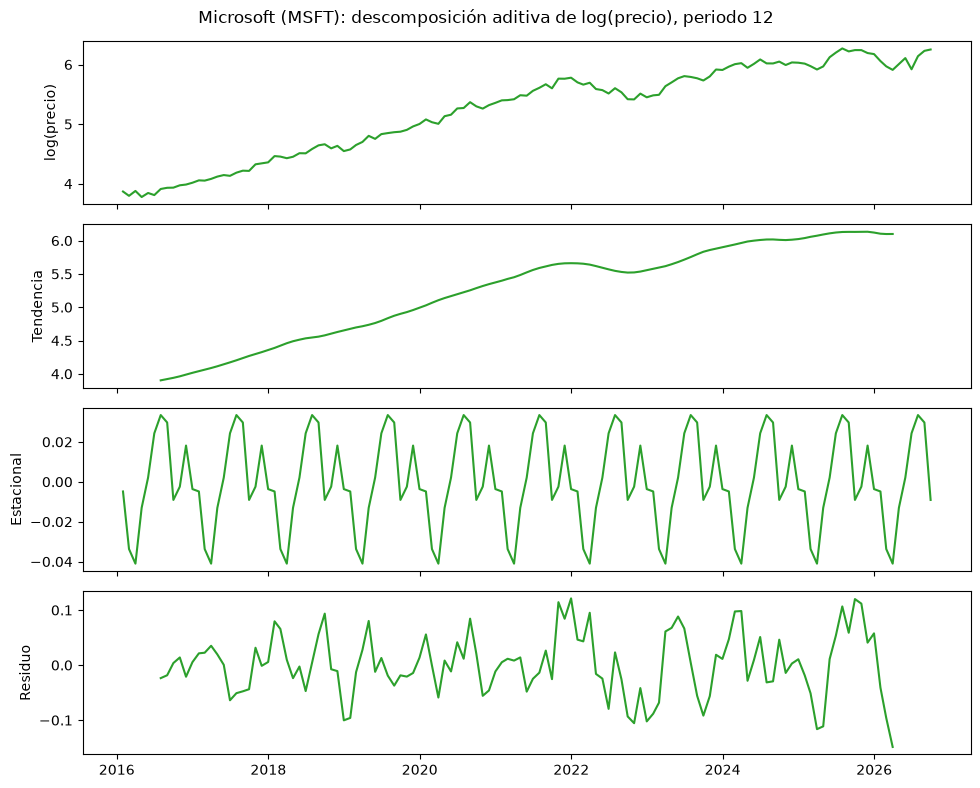

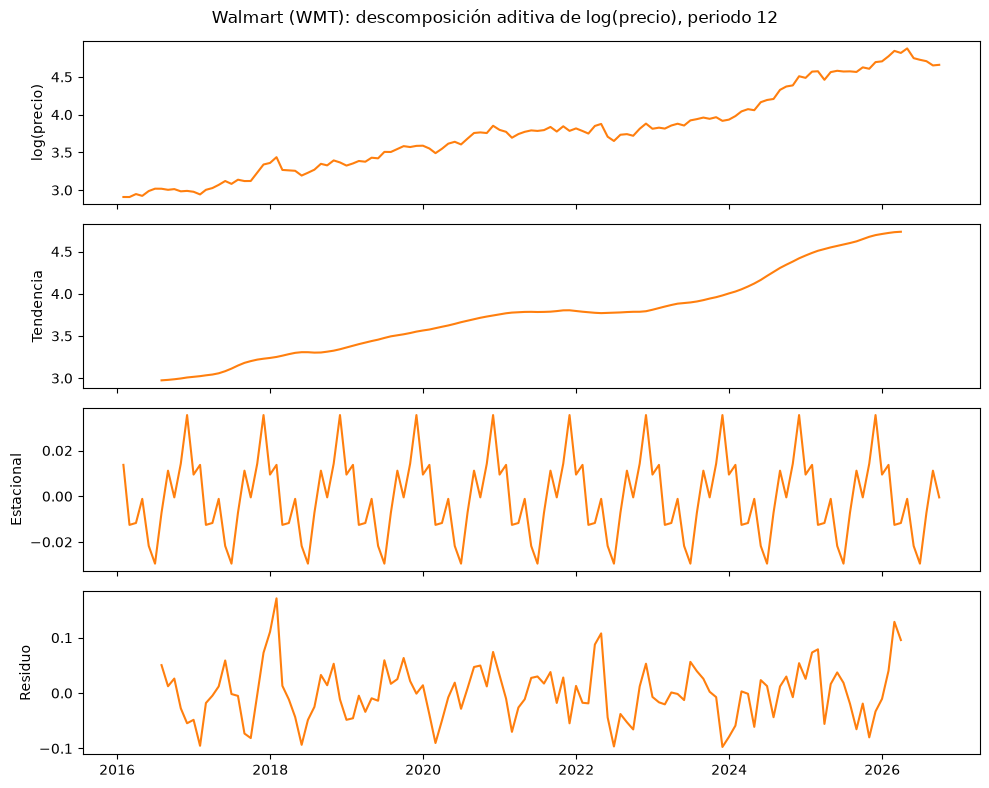

In [4]:
# ---- Descomposición (aditiva sobre log) y gráficos --------------------------
resultados = {}
for s, info in ACTIVOS.items():
    d = seasonal_decompose(log_mensual[s], model="additive", period=PERIODO)
    resultados[s] = d

    fig, ejes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    for eje, (serie, etiqueta) in zip(ejes, [(d.observed, "log(precio)"), (d.trend, "Tendencia"),
                                            (d.seasonal, "Estacional"), (d.resid, "Residuo")]):
        eje.plot(serie, color=info["color"])
        eje.set_ylabel(etiqueta)
    fig.suptitle(f"{info['nombre']} ({s}): descomposición aditiva de log(precio), periodo {PERIODO}")
    fig.tight_layout()
    fig.savefig(DIR_OUT / f"descomposicion_{s}.png", dpi=150)
    plt.show()

In [ ]:
# ---- Interpretación ---
#
# TENDENCIA: los tres activos suben de forma sostenida entre 2016 y 2026.
#   - JPM  : ≈ 20.6 % anual compuesto
#   - MSFT : ≈ 25.5 % anual compuesto (la más fuerte)
#   - WMT  : ≈ 20.0 % anual compuesto
#   En JPM, la tendencia se aplana en 2022 tras la subida de 2021.
#
# ESTACIONALIDAD: débil en los tres. La diferencia entre el mejor y el peor mes del año
#   (≈ 7-9 %) es del mismo orden que el residuo típico (≈ 5-6 %), así que el patrón
#   mensual explica poco frente al ruido.
#   - JPM  : mejor mes enero, peor septiembre
#   - MSFT : mejor mes julio, peor marzo
#   - WMT  : mejor mes noviembre, peor junio
#
# RESIDUO: recoge lo que no explican ni la tendencia ni la estacionalidad (shocks de mercado).
#   - JPM  : mayor shock en marzo de 2020 (≈ -16 %)
#   - MSFT : mayor shock en marzo de 2026 (≈ -14 %)
#   - WMT  : mayor shock en enero de 2018 (≈ +19 %)
#
# MODELO: en el contraste, el multiplicativo deja el residuo más estable en los tres activos
#   (correlación tendencia-|residuo| más cercana a 0), lo que respalda usar log + aditivo.
#   Esta descomposición es solo descriptiva: no se usa para predecir.